In [2]:
import zipfile
import os

zip_path = "/content/Model_Inversion.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall("/content")

print("Files extracted successfully!")
print(os.listdir("/content"))

Files extracted successfully!
['.config', 'Model_Inversion.zip', 'traditional_ml_language_model_inversion', 'sample_data']


In [3]:
%cd /content/traditional_ml_language_model_inversion
!pip install -r requirements.txt

/content/traditional_ml_language_model_inversion


In [4]:
import os

required_files = [
    "config.py",
    "dataset.py",
    "features.py",
    "model.py",
    "train.py",
    "evaluate.py",
    "predict.py",
    "visualize.py",
]

for filename in required_files:
    print(filename, "OK" if os.path.exists(filename) else "MISSING")


config.py OK
dataset.py OK
features.py OK
model.py OK
train.py OK
evaluate.py OK
predict.py OK
visualize.py OK


In [5]:
from dataset import make_prompts

df = make_prompts()

print("Dataset size:", len(df))
display(df.head(10))

Dataset size: 100


,prompt_id,prompt,family
0,p00_00,Write a short description of a city park.,task_0
1,p00_01,Explain three benefits of a city park.,task_1
2,p00_02,Suggest a creative project involving a city park.,task_2
3,p00_03,Give a beginner-friendly guide to a city park.,task_3
4,p00_04,List possible challenges related to a city park.,task_4
5,p00_05,Write a cheerful announcement about a city park.,task_5
6,p00_06,Compare two approaches to improving a city park.,task_6
7,p00_07,Create five questions about a city park.,task_7
8,p00_08,Describe a future version of a city park.,task_8
9,p00_09,Write a brief fictional scene featuring a city...,task_9


In [6]:
!python train.py --limit 100 --temperature 1.0 --top-k 20


config.json: 100% 762/762 [00:00<00:00, 2.42MB/s]
tokenizer_config.json: 100% 26.0/26.0 [00:00<00:00, 88.4kB/s]
vocab.json: 100% 1.04M/1.04M [00:00<00:00, 4.98MB/s]
merges.txt: 100% 456k/456k [00:00<00:00, 3.82MB/s]
tokenizer.json: 100% 1.36M/1.36M [00:00<00:00, 2.40MB/s]

model.safetensors: downloading bytes:  57% 201M/353M [00:02<00:00, 207MB/s, 16.2MB/s  ]
model.safetensors: downloading bytes:  75% 264M/353M [00:02<00:00, 149MB/s, 22.4MB/s  ]
model.safetensors: downloading bytes:  86% 305M/353M [00:03<00:00, 123MB/s, 25.9MB/s  ]
model.safetensors: downloading bytes: 100% 312M/312M [00:03<00:00, 91.4MB/s, 26.4MB/s  ]
model.safetensors: reconstructing file: 100% 353M/353M [00:03<00:00, 103MB/s, 31.2MB/s  ]
Loading weights: 100% 76/76 [00:00<00:00, 4240.00it/s]
generation_config.json: 100% 124/124 [00:00<00:00, 487kB/s]

ridge
 {
  "exact_match_accuracy": 0.0,
  "token_precision_micro": 0.6996031746031747,
  "token_recall_micro": 0.7045238095238094,
  "token_f1_micro": 0.70093543058248

In [7]:
import json

with open("artifacts/metrics.json", "r") as f:
    results = json.load(f)

print(json.dumps(results, indent=2))

{
  "settings": {
    "limit": 100,
    "temperature": 1.0,
    "top_k": 20,
    "model": "distilgpt2"
  },
  "results": {
    "ridge": {
      "exact_match_accuracy": 0.0,
      "token_precision_micro": 0.6996031746031747,
      "token_recall_micro": 0.7045238095238094,
      "token_f1_micro": 0.7009354305824894,
      "mean_retrieval_cosine_similarity": 0.6967512413072258
    },
    "random_forest": {
      "exact_match_accuracy": 0.0,
      "token_precision_micro": 0.712857142857143,
      "token_recall_micro": 0.7011904761904763,
      "token_f1_micro": 0.7053798750269338,
      "mean_retrieval_cosine_similarity": 0.8418043115250406
    }
  }
}


VISUALIZING CHARTS


In [8]:
!python visualize.py

Saved figures/model_comparison.png


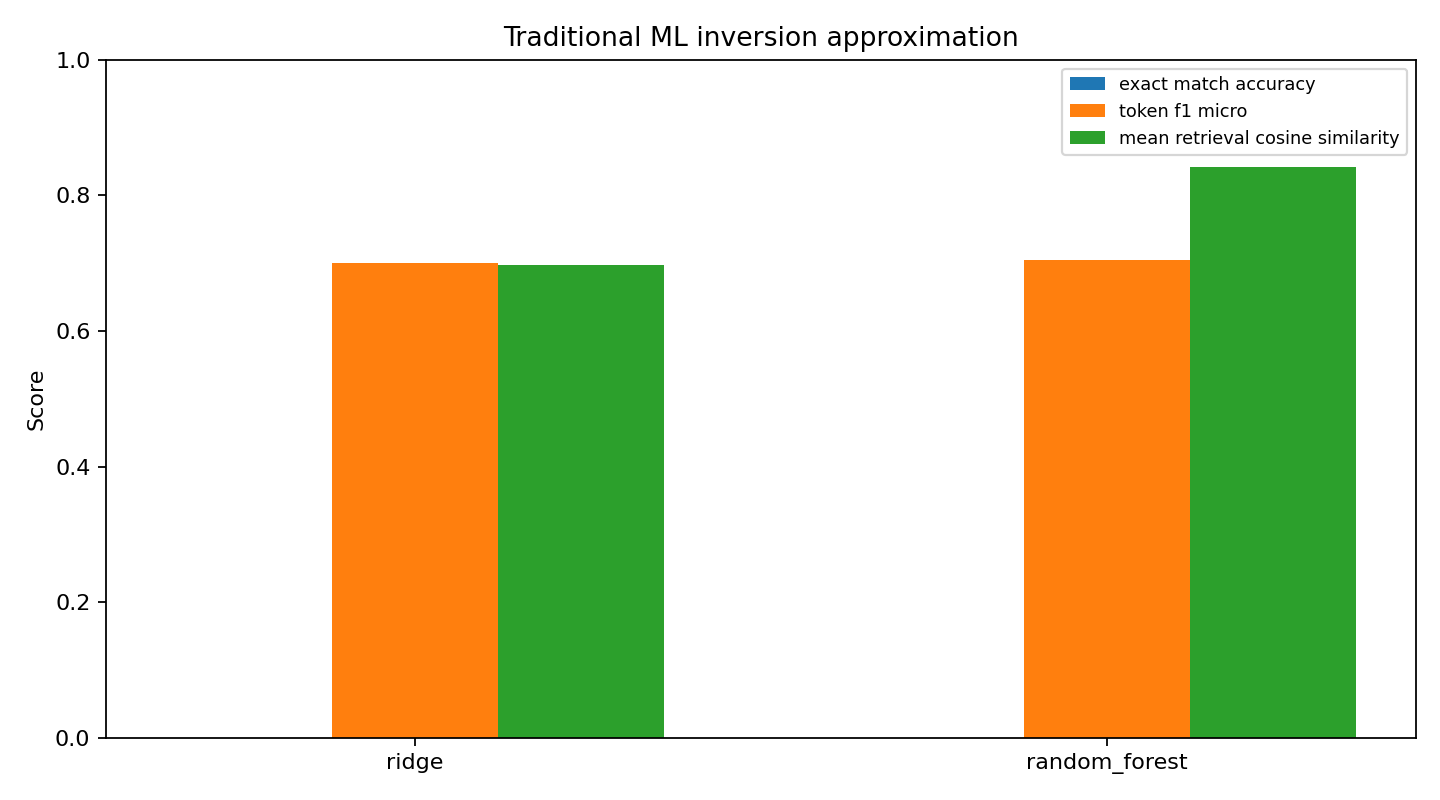

In [9]:
from IPython.display import display, Image

display(Image(filename="figures/model_comparison.png"))

In [10]:
import numpy as np
from config import ARTIFACT_DIR
from features import ProbabilityExtractor
from model import RidgeInverter

data = np.load(
    ARTIFACT_DIR / "features.npz",
    allow_pickle=True
)

X = data["X"]
prompts = data["prompts"].tolist()
train_idx = data["train_idx"]
test_idx = data["test_idx"]

model = RidgeInverter().fit(
    X[train_idx],
    [prompts[i] for i in train_idx]
)

i = int(test_idx[0])

prediction, similarity = model.predict(X[i:i+1])

print("GROUND TRUTH (evaluation only):")
print(prompts[i])

print("\nRETRIEVED CANDIDATE:")
print(prediction[0])

print("\nCOSINE SIMILARITY:")
print(round(float(similarity[0]), 4))

GROUND TRUTH (evaluation only):
Give a beginner-friendly guide to an electric bicycle.

RETRIEVED CANDIDATE:
Give a beginner-friendly guide to a city park.

COSINE SIMILARITY:
0.6907
